In [17]:
import numpy as np
import pandas as pd

In [18]:
from abc import ABC, abstractmethod
from typing import Tuple

In [19]:
class BaseModel(ABC):
    def __init__(self, learning_rate = 0.01, iters = 1000):
        self.learning_rate = learning_rate
        self.iters = iters
        self.w = None
        self.b = 0
        
    @abstractmethod
    def predict(self, X) -> np.ndarray:
        pass
        
    @abstractmethod
    def loss(self, y, pred_y) -> float:
        pass
    
    @abstractmethod
    def gradient(self, X, y, pred_y) -> Tuple[np.ndarray, float]:
        pass
    
    def update(self, dw, db):
        self.w -= self.learning_rate * dw
        self.b -= self.learning_rate * db
    
    def fit(self, X, y):
        self.history = []
        self.w = np.zeros(X.shape[1])
        self.b = 0.0
        
        for _ in range(self.iters):
            pred_y = self.predict(X)
            self.history.append(self.loss(y, pred_y))
            dw, db = self.gradient(X, y, pred_y)
            self.update(dw, db)
            
        return self
    
    def score(self, X, y):
        pred = self.predict(X)
        ss_res = np.sum((y - pred) ** 2)
        ss_tot = np.sum((y - np.mean(y)) ** 2)
        return 1 - ss_res / ss_tot
    
    

In [20]:
class LinearRegression(BaseModel):
    def predict(self, X):
        return X @ self.w + self.b

    def loss(self, y, pred_y):
        return np.mean((y - pred_y) ** 2)

    def gradient(self, X, y, pred_y):
        n = X.shape[0]
        error = pred_y - y
        dw = (2 / n) * X.T @ error
        db = (2 / n) * np.sum(error)
        return dw, db

In [21]:
try:
    BaseModel()
    print("FAIL: BaseModel should not be instantiable")
except TypeError as e:
    print("PASS: abstract check ->", e)

PASS: abstract check -> Can't instantiate abstract class BaseModel without an implementation for abstract methods 'gradient', 'loss', 'predict'


In [22]:
X = np.random.randn(100, 1)
y = 3 * X[:, 0] + 2

In [23]:
m1 = LinearRegression(learning_rate=0.1, iters=500).fit(X, y)

In [24]:

X = np.random.randn(200, 3)
true_w, true_b = np.array([1.5, -2.0, 0.7]), 4.0
y = X @ true_w + true_b + 0.1 * np.random.randn(200)

In [25]:
m2 = LinearRegression(learning_rate=0.1, iters=2000).fit(X, y)
sol = np.linalg.lstsq(np.c_[X, np.ones(len(X))], y, rcond=None)[0]

In [26]:
def num_grad(model, X, y, eps=1e-6):
    dw = np.zeros_like(model.w)
    for i in range(len(model.w)):
        model.w[i] += eps;  lp = model.loss(y, model.predict(X))
        model.w[i] -= 2*eps; lm = model.loss(y, model.predict(X))
        model.w[i] += eps
        dw[i] = (lp - lm) / (2 * eps)
    model.b += eps;  lp = model.loss(y, model.predict(X))
    model.b -= 2*eps; lm = model.loss(y, model.predict(X))
    model.b += eps
    return dw, (lp - lm) / (2 * eps)

In [27]:
m3 = LinearRegression()
m3.w, m3.b = np.random.randn(3), 0.5       # arbitrary non-optimal point
dw, db = m3.gradient(X, y, m3.predict(X))
ndw, ndb = num_grad(m3, X, y)

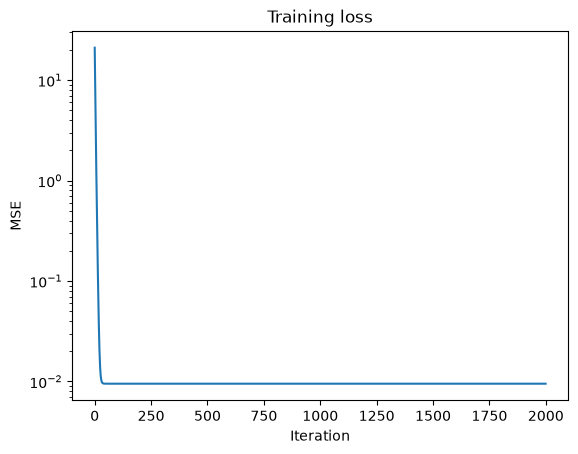

In [28]:
import matplotlib.pyplot as plt
plt.plot(m2.history)
plt.yscale("log")
plt.xlabel("Iteration"); plt.ylabel("MSE"); plt.title("Training loss")
plt.show()

In [29]:
m2.score(X,y)

np.float64(0.9986874688058297)